# Mini-project 2: Reliability of a Stay Cable in a Cable-Stayed Bridge

**Student Name:** Amilcar Diaz

**CCID:** adiazgar

Identify a problem from your own research area, professional field, or an engineering application of interest that involves uncertainty. Your task is to 1) describe the probability models and relevant model parameters or statistics for the important uncertain quantities or basic random variables; 2) define a quantity of interest that is a function of the basic random variables and is meaningful to you or engineers in the relevant field; 3) perform probabilistic analyses to the best of your ability. Depending on the problem, this may include calculating its statistical moments and/or PDF, evaluating the linear correlation between the quantity of interest and basic random variables, or estimating the probability of one or more events of interest; and 4) identify and read a research paper related to the problem you selected, followed by a brief summary of what you understand and what remains unclear at this point after you took this course.

## 1. Probability models of the basic random variables

Stay cables carry the deck loads of a cable-stayed bridge to the pylons, so their tension is one of the most important quantities to monitor. If the tension is too high, the cable may approach its capacity; if it changes over time, it may indicate damage, loss of anchorage or changes in the structure.

This mini-project analyzes a hypothetical stay cable of a cable-stayed bridge. All the cable properties, dimensions, loads and measured values used in this notebook are assumed to illustrate the problem and do not correspond to a real bridge or to a real monitoring campaign.

A common way to estimate the tension of a cable in service is the vibration method: by measuring the acceleration of the cable, the frequency at which it vibrates can be determined, and the tension is then estimated with the taut-string formula:

$$T_{med} = 4\,m\,L^2\left(\frac{f_n}{n}\right)^2 \tag{1}$$

where $T_{med}$ is the permanent tension (N), $m$ is the total mass per unit length (kg/m), $L$ is the effective length (m), $f_n$ is the natural frequency of mode $n$ (Hz) and $n$ is the mode number. For an ideal taut string, the natural frequencies of the higher modes are multiples of the fundamental frequency ($f_n = n\,f_1$), so the ratio $f_n/n$ is the same for any mode. This formula assumes an ideal taut string, so the bending stiffness of the cable, the sag (catenary effect) and the effect of the dampers are neglected. In this example, the fundamental mode ($n = 1$) is used, so Eq. (1) becomes:

$$T_{med} = 4\,m\,L^2 f_1^2 \tag{2}$$

The measurement is assumed to be taken under ambient conditions, without traffic on the bridge, so $T_{med}$ represents the permanent tension of the cable (due to dead load only). The additional tension caused by traffic is considered separately as the live load $T_{LL}$. In this example, the fundamental frequency $f_1$ is assumed to come from such an analysis; the value used is not a real measurement and is only intended to illustrate the problem.

The analyzed cable is assumed to be made of 37 strands of 15.7 mm, grade 1860 MPa (ASTM A416-16), with a minimum breaking strength of 279 kN per strand. The mean values of $m$, $L$ and $f_1$ are also assumed for this hypothetical cable, while the coefficients of variation and distributions of $R$ and $T_{LL}$ are taken from the cited references.

| Variable | Mean | CV | Std. deviation | Distribution | Justification |
|---|---|---|---|---|---|
| $R$, resistance | 37 × 279 kN = 10 323 kN | 0.015 | 154.8 kN | Normal | Ali, Katsuchi and Yamada (2018); Nowak (1999) |
| $m$, total mass per unit length | 54 kg/m | 0.02 | 1.08 kg/m | Normal | Assumed (manufacturing tolerances) |
| $L$, effective length | 150 m | 0.03 | 4.50 m | Normal | Assumed (uncertainty due to dampers and anchorages) |
| $f_1$, fundamental frequency ($n$ = 1) | 0.96 Hz | 0.01 | 0.0096 Hz | Normal | Assumed (illustrative value from a vibration measurement) |
| $T_{LL}$, live load | 1.18 × 1000 kN = 1180 kN | 0.18 | 212.4 kN | Lognormal | Pushka et al. (2022); Kulicki et al. (2007) |

**Live load:** the nominal CL-800 live load of the Canadian Highway Bridge Design Code (CSA S6:19) produces a nominal tension in the analyzed cable equal to $T_{LL,n}$ = 1000 kN. This value depends on the geometry and properties of the bridge and on the position of the cable, and it is assumed for this example. The bias factor (1.18) and the coefficient of variation (0.18) of the live load were obtained in the cited studies for other live load models, not for the CL-800; they are applied to the CL-800 load only to illustrate the problem. The parameters of the lognormal distribution, with $\delta_{LL} = CV_{LL} = 0.18$, are:

$$\zeta_{LL}^2 = \sigma_{\ln T_{LL}}^2 = \ln\left(1 + \delta_{LL}^2\right) = \ln\left(1 + 0.18^2\right) = 0.03189, \qquad \zeta_{LL} = 0.1786 \tag{3}$$

$$\lambda_{LL} = \mu_{\ln T_{LL}} = \ln \mu_{LL} - \frac{1}{2}\ln\left(1 + \delta_{LL}^2\right) = \ln(1180) - \frac{1}{2}\ln\left(1 + 0.18^2\right) = 7.0733 - 0.0159 = 7.0573 \tag{4}$$

**Independence:** the variables are assumed to be statistically independent because they come from different sources, so the variance obtained with the first-order approximation does not include covariance terms.

## 2. Quantity of interest

The quantity of interest is the **limit state function** $g$, which compares the resistance of the cable with the total tension (permanent tension plus live load). The cable fails if $g < 0$.

The permanent tension $T_{med}$ is an intermediate quantity, given by the taut-string formula in Eq. (1). Then, the limit state function is:

$$g = R - \left(T_{med} + T_{LL}\right) \tag{5}$$

## 3. Probabilistic analysis

### 3.1 Statistical moments (First-Order Approximation)

The first-order approximation expands a function $Y = g(X_1, X_2, \ldots, X_k)$ in a Taylor series around the mean values of the input variables and keeps only the first-order (linear) terms. With this approximation, the mean of the function is obtained by evaluating the function at the mean values of the input variables:

$$\mu_Y \approx g\left(\mu_{X_1}, \mu_{X_2}, \ldots, \mu_{X_k}\right) \tag{6}$$

and, since the variables are independent, the variance has no covariance terms:

$$\sigma_Y^2 \approx \sum_{i=1}^{k} \left(\frac{\partial g}{\partial x_i}\right)^2_{\mu} \sigma_{X_i}^2 \tag{7}$$

where the partial derivatives are evaluated at the mean values.

**Mean of the permanent tension:** applying Eq. (6) to Eq. (2), the taut-string formula is evaluated at the mean values of $m$, $L$ and $f_1$:

$$\mu_{T} \approx 4\,\mu_m\,\mu_L^2\,\mu_{f_1}^2 = 4\,(54)\,(150)^2\,(0.96)^2 = 4\,478\,976\ \text{N} = 4479.0\ \text{kN} \tag{8}$$

Partial derivatives of $T_{med}$ evaluated at the mean values:

$$\frac{\partial T_{med}}{\partial m} = 4\,L^2 f_1^2 = 4\,(150)^2\,(0.96)^2 = 82\,944\ \text{N per kg/m} = 82.94\ \text{kN per kg/m} \tag{9}$$

$$\frac{\partial T_{med}}{\partial L} = 8\,m\,L\,f_1^2 = 8\,(54)\,(150)\,(0.96)^2 = 59\,720\ \text{N/m} = 59.72\ \text{kN/m} \tag{10}$$

$$\frac{\partial T_{med}}{\partial f_1} = 8\,m\,L^2 f_1 = 8\,(54)\,(150)^2\,(0.96) = 9\,331\,200\ \text{N/Hz} = 9331.2\ \text{kN/Hz} \tag{11}$$

**Standard deviation of the permanent tension:** applying Eq. (7) with the derivatives of Eqs. (9) to (11):

$$\sigma_T^2 \approx (82.94 \times 1.08)^2 + (59.72 \times 4.50)^2 + (9331.2 \times 0.0096)^2 = 89.58^2 + 268.74^2 + 89.58^2 = 88\,269\ \text{kN}^2 \tag{12}$$

$$\sigma_T \approx 297.1\ \text{kN}, \qquad CV_T = \frac{297.1}{4479.0} = 0.066 \tag{13}$$

| Variable | Contribution to $\sigma_T^2$ |
|---|---|
| $m$ | 8 024 kN² (9.1 %) |
| $L$ | 72 220 kN² (81.8 %) |
| $f_1$ | 8 024 kN² (9.1 %) |

The effective length $L$ dominates the uncertainty of the tension, because it appears squared in Eq. (2) and has the largest coefficient of variation.

**Mean of the limit state function:** applying Eq. (6) to Eq. (5):

$$\mu_g \approx \mu_R - \mu_T - \mu_{LL} = 10\,323 - 4479.0 - 1180 = 4664.0\ \text{kN} \tag{14}$$

**Standard deviation of the limit state function:** the derivatives of $g$ are $\partial g / \partial R = 1$, $\partial g / \partial T_{LL} = -1$, and $\partial g / \partial x_i = -\partial T_{med} / \partial x_i$ for $m$, $L$ and $f_1$, so:

$$\sigma_g^2 \approx \sigma_R^2 + \sigma_T^2 + \sigma_{LL}^2 = 154.8^2 + 297.1^2 + 212.4^2 = 157\,360\ \text{kN}^2 \tag{15}$$

$$\sigma_g \approx 396.7\ \text{kN} \tag{16}$$

### 3.2 Probability of failure

The cable fails when $g < 0$. Assuming that $g$ follows a normal distribution with the mean and standard deviation obtained in Section 3.1, the probability of failure is:

$$P_f = P(g < 0) = \Phi\left(\frac{0 - \mu_g}{\sigma_g}\right) = \Phi\left(\frac{0 - 4664.0}{396.7}\right) = \Phi(-11.76) = 3.2 \times 10^{-32} \tag{17}$$

where $\Phi$ is the cumulative distribution function of the standard normal distribution. This probability is extremely small, so the failure of the hypothetical cable under these conditions is practically impossible.

### 3.3 Monte Carlo verification and PDF

**Permanent tension.** Monte Carlo simulation is applied to verify the PDF of the permanent tension obtained with the first-order approximation. Assuming that $T_{med}$ is normally distributed, with the mean and standard deviation of Eqs. (8) and (13), its PDF is:

$$f_{T_{med}}(t) = \frac{1}{\sigma_T\sqrt{2\pi}} \exp\left[-\frac{1}{2}\left(\frac{t - \mu_T}{\sigma_T}\right)^2\right] = \frac{1}{297.1\sqrt{2\pi}} \exp\left[-\frac{1}{2}\left(\frac{t - 4479.0}{297.1}\right)^2\right] \tag{18}$$

Samples of $m$, $L$ and $f_1$ are generated from their distributions (Section 1), $T_{med}$ is computed with Eq. (1) for each sample, and the histogram of the results is compared with Eq. (18).

T_med (Monte Carlo): mean = 4483.8 kN, std = 297.2 kN
T_med (first-order): mean = 4479.0 kN, std = 297.1 kN


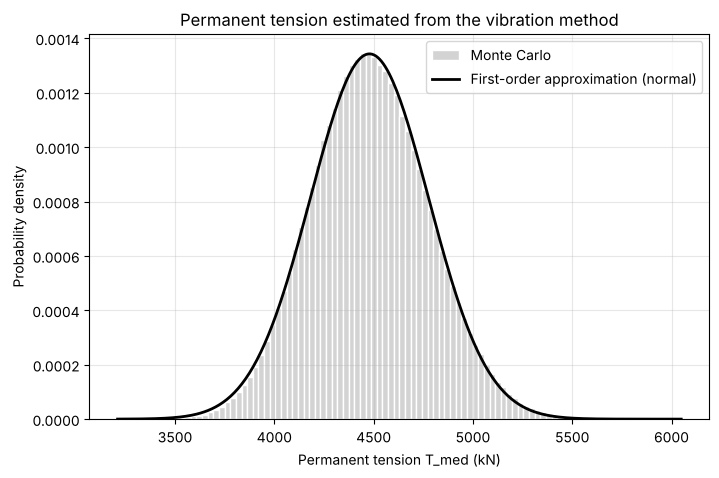

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

N = 1_000_000
rng = np.random.default_rng(42)

# Parameters of m, L and f1 (Section 1)
mu_m, sigma_m = 54.0, 1.08
mu_L, sigma_L = 150.0, 4.5
mu_f, sigma_f = 0.96, 0.0096
n = 1

# First-order approximation results for T_med
mu_T_fo, sigma_T_fo = 4479.0, 297.1   # kN, Eqs. (8) and (13)

# Samples of m, L and f1
m_s = rng.normal(mu_m, sigma_m, N)
L_s = rng.normal(mu_L, sigma_L, N)
f_s = rng.normal(mu_f, sigma_f, N)

# Permanent tension from simulation
T_s = 4 * m_s * L_s**2 * (f_s / n)**2 / 1000

print(f"T_med (Monte Carlo): mean = {T_s.mean():.1f} kN, std = {T_s.std():.1f} kN")
print(f"T_med (first-order): mean = {mu_T_fo:.1f} kN, std = {sigma_T_fo:.1f} kN")

# Histogram
T_line = np.linspace(T_s.min(), T_s.max(), 300)

plt.figure(figsize=(8, 5))
plt.hist(T_s, bins=100, density=True, color="lightgray", edgecolor="white", label="Monte Carlo")
plt.plot(T_line, norm.pdf(T_line, mu_T_fo, sigma_T_fo), color="black", linewidth=2, label="First-order approximation (normal)")
plt.xlabel("Permanent tension T_med (kN)")
plt.ylabel("Probability density")
plt.title("Permanent tension estimated from the vibration method")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

**Limit state function.** Monte Carlo simulation is applied to verify the PDF of the limit state function obtained with the first-order approximation. Assuming that $g$ is normally distributed, with the mean and standard deviation of Eqs. (14) and (16), its PDF is:

$$f_g(x) = \frac{1}{\sigma_g\sqrt{2\pi}} \exp\left[-\frac{1}{2}\left(\frac{x - \mu_g}{\sigma_g}\right)^2\right] = \frac{1}{396.7\sqrt{2\pi}} \exp\left[-\frac{1}{2}\left(\frac{x - 4664.0}{396.7}\right)^2\right] \tag{19}$$

Samples of $R$ and $T_{LL}$ are generated from their distributions (Section 1), $g$ is computed with Eq. (5) using the samples of $T_{med}$ from the previous cell, and the histogram of the results is compared with Eq. (19). The probability of failure is also estimated as the fraction of samples with $g < 0$.

g (Monte Carlo): mean = 4659.0 kN, std = 396.8 kN
g (first-order): mean = 4664.0 kN, std = 396.7 kN
Pf Monte Carlo < 1e-06  (0 failures in 1000000 samples)


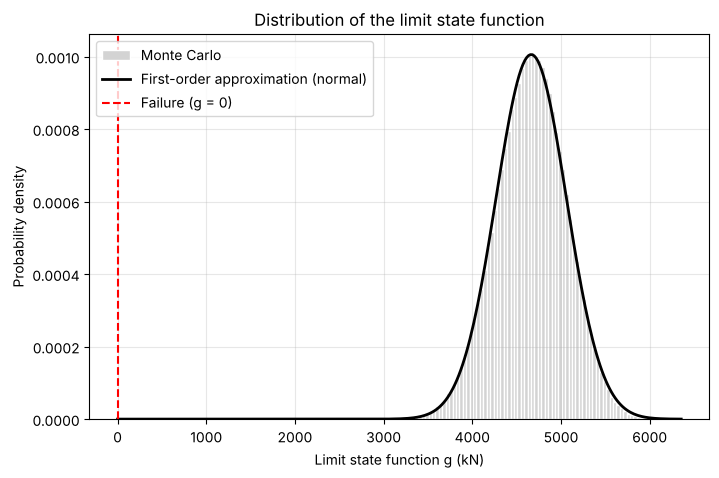

In [ ]:
mu_R, sigma_R = 10323.0, 154.845
lambda_LL, zeta_LL = 7.0573, 0.1786

# First-order approximation results for g 
mu_g_fo, sigma_g_fo = 4664.0, 396.7

# Samples of R and T_LL
R_s = rng.normal(mu_R, sigma_R, N)
LL_s = rng.lognormal(lambda_LL, zeta_LL, N)

# Limit state function from simulation
g_s = R_s - T_s - LL_s
n_fail = np.sum(g_s < 0)

print(f"g (Monte Carlo): mean = {g_s.mean():.1f} kN, std = {g_s.std():.1f} kN")
print(f"g (first-order): mean = {mu_g_fo:.1f} kN, std = {sigma_g_fo:.1f} kN")
if n_fail > 0:
    print(f"Pf Monte Carlo = {n_fail / N:.3e}  ({n_fail} failures)")
else:
    print(f"Pf Monte Carlo < {1 / N:.0e}  (0 failures in {N} samples)")

# Histogram
g_line = np.linspace(min(g_s.min(), 0), g_s.max(), 300)

plt.figure(figsize=(8, 5))
plt.hist(g_s, bins=100, density=True, color="lightgray", edgecolor="white", label="Monte Carlo")
plt.plot(g_line, norm.pdf(g_line, mu_g_fo, sigma_g_fo), color="black", linewidth=2, label="First-order approximation (normal)")
plt.axvline(0, color="red", linestyle="--", label="Failure (g = 0)")
plt.xlabel("Limit state function g (kN)")
plt.ylabel("Probability density")
plt.title("Distribution of the limit state function")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

The first-order approximation and Monte Carlo give practically the same mean and standard deviation, so the nonlinearity of $g$ and the lognormal live load have a small effect for these coefficients of variation. However, Monte Carlo cannot verify the probability of failure: with $10^6$ samples no failures are observed, since the expected number of failures would be $10^6 \times 3.2 \times 10^{-32} \approx 0$.

## 4. Research paper summary

**Hou, N., Sun, L., & Chen, L. (2020).** Cable reliability assessments for cable-stayed bridges using identified tension forces and monitored loads. *Journal of Bridge Engineering, 25*(7), Article 05020003. https://doi.org/10.1061/(ASCE)BE.1943-5592.0001573

**What I understood:**

To analyze a real case study of a bridge, each variable that affects the cable tension must be considered separately, mainly temperature, wind and traffic, and its probability distribution must be characterized with data measured on site over time.

However, the paper shows that using only this approach can be very conservative, because when the loads are combined, it is implicitly assumed that the maximum values of all of them occur at the same time, which is very unlikely in practice. For this reason, it is also recommended to analyze the tension measured from the frequency of the cable, which already reflects the actual combination of all the variables in a single measurement.

**What remains unclear:**

It is not clear to me how to combine these two approaches, the analysis of each load separately and the directly measured tension, to obtain a more suitable probabilistic model.

## References

- Ali, K., Katsuchi, H., & Yamada, H. (2018). Parametric study on cable safety of cable-stayed bridge considering ultimate and fatigue limit states. *Journal of Structural Engineering, A (JSCE), 64A*, 99–108. https://doi.org/10.11532/structcivil.64A.99

- ASTM International. (2016). *Standard specification for low-relaxation, seven-wire steel strand for prestressed concrete* (ASTM A416/A416M-16). https://doi.org/10.1520/A0416_A0416M-16

- CSA Group. (2019). *Canadian highway bridge design code* (CSA S6:19). CSA Group.

- Hou, N., Sun, L., & Chen, L. (2020). Cable reliability assessments for cable-stayed bridges using identified tension forces and monitored loads. *Journal of Bridge Engineering, 25*(7), Article 05020003. https://doi.org/10.1061/(ASCE)BE.1943-5592.0001573

- Kulicki, J. M., Prucz, Z., Clancy, C. M., Mertz, D. R., & Nowak, A. S. (2007). *Updating the calibration report for AASHTO LRFD code* (NCHRP Project 20-7/186). Transportation Research Board.

- Nowak, A. S. (1999). *Calibration of LRFD bridge design code* (NCHRP Report 368). Transportation Research Board, National Research Council.

- Pushka, A., Regehr, J. D., Fiorillo, G., Mufti, A., & Algohi, B. (2022). Reliability analysis of typical highway bridges in Manitoba designed to the Modified HSS-25 live load model. *Canadian Journal of Civil Engineering, 49*(6), 899–909. https://doi.org/10.1139/cjce-2021-0031

